# Reconnaissance de panneaux de signalisation
Faïkidine, Arno et Clément

L'objectif est de reconnaître le type d'un panneau à partir de son image. On compare un réseau dense à un CNN sur GTSRB, puis on examine les erreurs du CNN.

Les deux modèles utilisent les mêmes données d'entraînement et de validation. Le test officiel sera utilisé après les expériences et le choix du modèle final.

## 1. Imports et réglages
On entraîne les deux modèles pendant **3 époques**, avec des lots de **64 images**. Un entraînement plus long sera testé ensuite.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Conv2D, MaxPooling2D
from tensorflow.keras.utils import to_categorical

TAILLE = 32
NB_CLASSES = 43
EPOCHS = 3
BATCH_SIZE = 64
SEED = 42

tf.keras.utils.set_random_seed(SEED)

## 2. Les données : GTSRB
On choisit GTSRB car les photos contiennent déjà un panneau. Cela permet de commencer par la classification.

- 43 catégories, avec des images couleur de tailles différentes au format PPM.
- 39 209 images dans l'ensemble d'entraînement officiel et 12 630 dans le test final, soit 51 839 au total.
- Les classes n'ont pas toutes le même nombre d'images. On affichera cette répartition.

Source : [archive des auteurs sur ERDA](https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/published-archive.html). Auteurs : J. Stallkamp, M. Schlipsing, J. Salmen et C. Igel, publication GTSRB, IJCNN 2011.

Conditions d'utilisation : la page de l'archive ne précise pas de licence.

L'ensemble d'entraînement officiel est partagé en train et validation. **Le test officiel est réservé à l'évaluation du modèle final.**

### Chargement des données

In [2]:
dossier_data = Path("data")
dossier_data.mkdir(exist_ok=True)

url = "https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/"
archive = tf.keras.utils.get_file(
    fname="GTSRB_Final_Training_Images.zip",
    origin=url + "GTSRB_Final_Training_Images.zip",
    cache_dir=str(Path.cwd()),
    cache_subdir="data"
)

with ZipFile(archive) as fichier_zip:
    fichier_zip.extractall(dossier_data)

dossier_images = dossier_data / "GTSRB" / "Final_Training" / "Images"

### Lecture des annotations
Chaque classe a un fichier CSV. On rassemble ces fichiers dans un tableau qui contient le chemin de l'image, sa classe et ses dimensions d'origine.

In [3]:
tableaux = []
for fichier_csv in sorted(dossier_images.glob("*/GT-*.csv")):
    tableau = pd.read_csv(fichier_csv, sep=";")
    tableau["chemin"] = tableau["Filename"].apply(lambda nom: str(fichier_csv.parent / nom))
    tableaux.append(tableau)

donnees = pd.concat(tableaux, ignore_index=True)
# Le début du nom indique la séquence de photos d'un même panneau.
# On ajoute la classe car les numéros de séquence sont réutilisés entre classes.
donnees["sequence"] = donnees["ClassId"].astype(str) + "_" + donnees["Filename"].str.split("_").str[0]

assert len(donnees) == 39209
assert donnees["ClassId"].nunique() == NB_CLASSES
print("Nombre d'images :", len(donnees))
print("Nombre de classes :", donnees["ClassId"].nunique())
print("Largeur min / max :", donnees["Width"].min(), donnees["Width"].max())
print("Hauteur min / max :", donnees["Height"].min(), donnees["Height"].max())
display(donnees.head())

Nombre d'images : 39209
Nombre de classes : 43
Largeur min / max : 25 243
Hauteur min / max : 25 225


,Filename,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,chemin,sequence
0,00000_00000.ppm,29,30,5,6,24,25,0,data/GTSRB/Final_Training/Images/00000/00000_0...,0_00000
1,00000_00001.ppm,30,30,5,5,25,25,0,data/GTSRB/Final_Training/Images/00000/00000_0...,0_00000
2,00000_00002.ppm,30,30,5,5,25,25,0,data/GTSRB/Final_Training/Images/00000/00000_0...,0_00000
3,00000_00003.ppm,31,31,5,5,26,26,0,data/GTSRB/Final_Training/Images/00000/00000_0...,0_00000
4,00000_00004.ppm,30,32,5,6,25,26,0,data/GTSRB/Final_Training/Images/00000/00000_0...,0_00000


,Classe,Panneau,Nombre d'images
0,0,Limitation 20 km/h,210
1,1,Limitation 30 km/h,2220
2,2,Limitation 50 km/h,2250
3,3,Limitation 60 km/h,1410
4,4,Limitation 70 km/h,1980
5,5,Limitation 80 km/h,1860
6,6,Fin de limitation 80 km/h,420
7,7,Limitation 100 km/h,1440
8,8,Limitation 120 km/h,1410
9,9,Dépassement interdit,1470


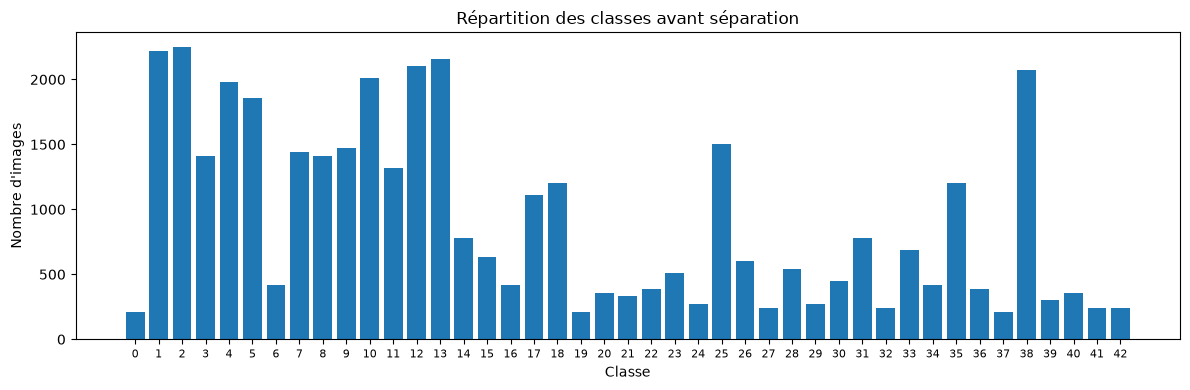

In [4]:
noms_classes = [
    "Limitation 20 km/h", "Limitation 30 km/h", "Limitation 50 km/h",
    "Limitation 60 km/h", "Limitation 70 km/h", "Limitation 80 km/h",
    "Fin de limitation 80 km/h", "Limitation 100 km/h", "Limitation 120 km/h",
    "Dépassement interdit", "Dépassement interdit aux poids lourds",
    "Priorité à la prochaine intersection", "Route prioritaire", "Cédez le passage",
    "Stop", "Circulation interdite", "Poids lourds interdits", "Sens interdit",
    "Danger", "Virage à gauche", "Virage à droite", "Double virage",
    "Chaussée déformée", "Chaussée glissante", "Chaussée rétrécie à droite",
    "Travaux", "Feux tricolores", "Passage piétons", "Enfants", "Cyclistes",
    "Neige ou verglas", "Animaux sauvages", "Fin des interdictions",
    "Tourner à droite", "Tourner à gauche", "Tout droit", "Tout droit ou à droite",
    "Tout droit ou à gauche", "Contournement par la droite", "Contournement par la gauche",
    "Rond-point", "Fin d'interdiction de dépasser", "Fin d'interdiction de dépasser pour poids lourds"
]

effectifs = donnees["ClassId"].value_counts().sort_index()
repartition = pd.DataFrame({
    "Classe": range(NB_CLASSES),
    "Panneau": noms_classes,
    "Nombre d'images": effectifs.to_numpy()
})
display(repartition)

plt.figure(figsize=(12, 4))
plt.bar(effectifs.index, effectifs.values)
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.title("Répartition des classes avant séparation")
plt.xticks(range(NB_CLASSES), fontsize=8)
plt.tight_layout()
plt.show()

Les classes contiennent entre 210 et 2 250 images avant séparation. Une bonne accuracy globale peut donc masquer des difficultés sur les classes peu représentées. On regardera aussi les scores par classe.

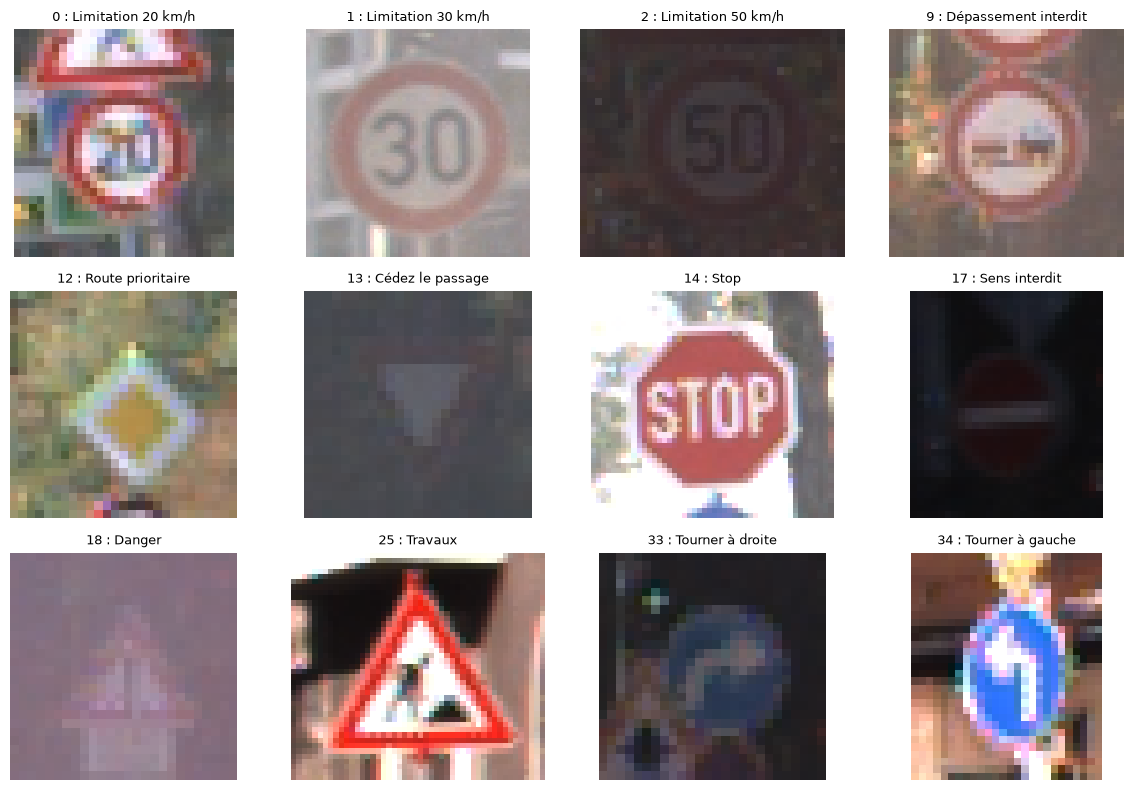

In [5]:
plt.figure(figsize=(12, 8))
classes_a_montrer = [0, 1, 2, 9, 12, 13, 14, 17, 18, 25, 33, 34]
for position, classe in enumerate(classes_a_montrer):
    ligne = donnees[donnees["ClassId"] == classe].iloc[0]
    with Image.open(ligne["chemin"]) as image:
        plt.subplot(3, 4, position + 1)
        plt.imshow(image)
    plt.title(f"{classe} : {noms_classes[classe]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

### Séparation train / validation
Plusieurs photos viennent du même panneau filmé à la suite. Si on répartit ces photos au hasard, des images presque identiques peuvent se retrouver dans le train et la validation.

On sépare donc les **séquences entières**, en gardant environ 80 % pour apprendre et 20 % pour valider. `stratify` garde une répartition proche des classes au niveau des séquences. La graine fixe permet de reprendre la même séparation pour tous les essais.

In [6]:
sequences = donnees[["sequence", "ClassId"]].drop_duplicates()
sequences_train, sequences_val = train_test_split(
    sequences, test_size=0.2, random_state=SEED, stratify=sequences["ClassId"]
)

donnees_train = donnees[donnees["sequence"].isin(sequences_train["sequence"])].reset_index(drop=True)
donnees_val = donnees[donnees["sequence"].isin(sequences_val["sequence"])].reset_index(drop=True)

assert set(donnees_train["sequence"]).isdisjoint(donnees_val["sequence"])
assert len(donnees_train) + len(donnees_val) == len(donnees)
assert donnees_train["ClassId"].nunique() == donnees_val["ClassId"].nunique() == NB_CLASSES
print("Train :", len(donnees_train), "images")
print("Validation :", len(donnees_val), "images")
print("Séquences communes : 0")

Train : 31350 images
Validation : 7859 images
Séquences communes : 0


### Préparation des images
On redimensionne en **32 × 32** pour garder un modèle rapide. On conserve les trois canaux RGB, car la couleur peut aider à reconnaître les panneaux. On garde toute l'image fournie, avec sa petite bordure.

Les pixels sont divisés par 255 pour être entre 0 et 1. Les labels sont encodés en one-hot : une ligne de 43 valeurs, avec un 1 pour la vraie classe.

In [7]:
def charger_images(tableau):
    x = np.empty((len(tableau), TAILLE, TAILLE, 3), dtype="float32")
    for i, chemin in enumerate(tableau["chemin"]):
        with Image.open(chemin) as image:
            image = image.convert("RGB").resize((TAILLE, TAILLE), Image.Resampling.BILINEAR)
            x[i] = np.asarray(image, dtype="float32") / 255.0
    labels = tableau["ClassId"].to_numpy(dtype="int32")
    return x, labels

x_train, labels_train = charger_images(donnees_train)
x_val, labels_val = charger_images(donnees_val)
y_train = to_categorical(labels_train, NB_CLASSES)
y_val = to_categorical(labels_val, NB_CLASSES)

print("x_train :", x_train.shape, " / y_train :", y_train.shape)
print("x_val :", x_val.shape, " / y_val :", y_val.shape)
print("Pixels min / max :", x_train.min(), x_train.max())
print("Exemple de label one-hot :", y_train[0])

x_train : (31350, 32, 32, 3)  / y_train : (31350, 43)
x_val : (7859, 32, 32, 3)  / y_val : (7859, 43)
Pixels min / max : 0.0 1.0
Exemple de label one-hot : [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 3. Essai 1 : réseau dense de référence
Ce réseau sert de référence pour mesurer ensuite l'apport des convolutions.

`Flatten` transforme les 32 × 32 × 3 valeurs en un vecteur de 3 072 valeurs. La couche dense combine ces entrées avec des poids et des biais. ReLU garde les valeurs positives et introduit une non-linéarité. Les 43 sorties Softmax donnent des probabilités dont la somme vaut 1.

Pendant la propagation avant, on calcule les prédictions. La cross-entropy mesure l'erreur par rapport aux labels one-hot. La rétropropagation calcule les gradients, puis Adam ajuste les poids et les biais pour réduire cette erreur. Keras réalise automatiquement ces étapes pendant l'entraînement.

**Réglages de départ :** Adam avec un learning rate de 0,001, batch de 64 images, 3 époques. L'accuracy est la proportion de bonnes réponses. Ces réglages restent identiques pour le CNN afin de comparer un premier changement d'architecture.

In [8]:
tf.keras.utils.set_random_seed(SEED)
model_dense = Sequential()
model_dense.add(Input(shape=(TAILLE, TAILLE, 3)))
model_dense.add(Flatten())
model_dense.add(Dense(128, activation="relu"))
model_dense.add(Dense(NB_CLASSES, activation="softmax"))

model_dense.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model_dense.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 398,891 (1.52 MB)

 Trainable params: 398,891 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
debut = perf_counter()
history_dense = model_dense.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2
)
duree_dense = perf_counter() - debut

Epoch 1/3


490/490 - 1s - 2ms/step - accuracy: 0.4382 - loss: 2.3573 - val_accuracy: 0.5750 - val_loss: 1.7695


Epoch 2/3


490/490 - 1s - 1ms/step - accuracy: 0.6993 - loss: 1.2620 - val_accuracy: 0.6801 - val_loss: 1.2492


Epoch 3/3


490/490 - 1s - 1ms/step - accuracy: 0.7908 - loss: 0.8903 - val_accuracy: 0.7313 - val_loss: 1.0243


### Courbes d'apprentissage
Si la loss du train baisse mais que celle de validation remonte durablement, cela peut indiquer du surapprentissage.

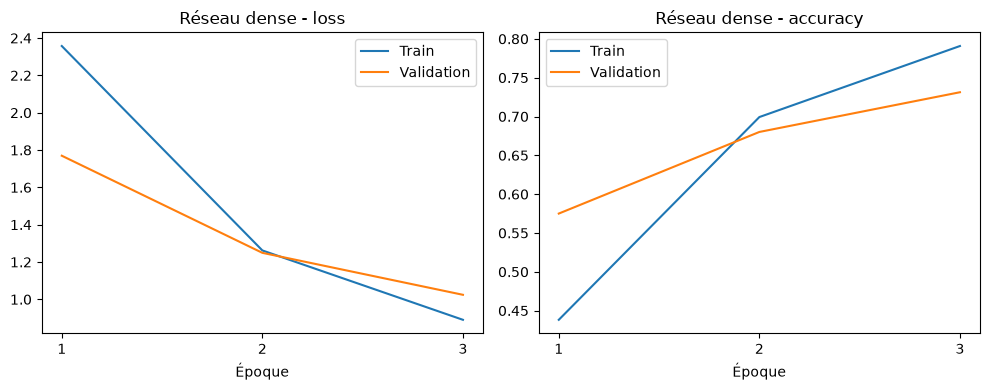

In [10]:
def afficher_courbes(history, nom):
    epochs = range(1, len(history.history["loss"]) + 1)
    plt.figure(figsize=(10, 4))
    for position, mesure in enumerate(["loss", "accuracy"]):
        plt.subplot(1, 2, position + 1)
        plt.plot(epochs, history.history[mesure], label="Train")
        plt.plot(epochs, history.history["val_" + mesure], label="Validation")
        plt.title(nom + " - " + mesure)
        plt.xlabel("Époque")
        plt.xticks(list(epochs))
        plt.legend()
    plt.tight_layout()
    plt.show()

afficher_courbes(history_dense, "Réseau dense")

Entre la première et la deuxième époque, la loss d'entraînement passe de **2,3573 à 1,2620**. Elle diminue fortement : le réseau corrige rapidement une partie de ses erreurs. Cela se retrouve aussi sur la validation, dont l'accuracy passe de **57,50 % à 68,01 %**.

À la troisième époque, la progression ralentit : l'accuracy de validation gagne encore **5,12 points**, contre **10,51 points** à l'époque précédente. La loss d'entraînement descend à **0,8903** et celle de validation à **1,0243**. Le modèle continue donc d'apprendre ; il n'a pas encore atteint un plateau sur ces courbes.

L'accuracy finale est de **79,08 % en train** et **73,13 % en validation**. Il reconnaît mieux les images d'entraînement, mais les deux loss baissent encore. On ne voit pas de dégradation de la validation qui indiquerait un surapprentissage net à ce stade.

Le réseau reçoit les pixels sous forme de liste. On essaie ensuite des convolutions pour apprendre des motifs locaux, comme des bords ou des formes, en réutilisant les mêmes filtres à plusieurs positions de l'image.

## 4. Essai 2 : petit CNN
Le CNN contient deux blocs convolution + pooling.

Un filtre 3 × 3 parcourt l'image couleur et combine les trois canaux pour produire une carte de caractéristiques (*feature map*). On utilise un stride de 1 et `padding="valid"` : le filtre avance d'un pixel et on n'ajoute pas de bordure. ReLU suit chaque convolution. Le max pooling 2 × 2 réduit les dimensions en gardant le maximum de chaque zone.

Le premier bloc a 32 filtres, le second 64. Après `Flatten`, une couche dense de 128 neurones et Softmax réalisent la classification.

| Couche | Sortie par image | Paramètres |
|---|---|---:|
| Entrée | 32 × 32 × 3 | 0 |
| Conv2D, 32 filtres 3 × 3 | 30 × 30 × 32 | 896 |
| MaxPooling 2 × 2 | 15 × 15 × 32 | 0 |
| Conv2D, 64 filtres 3 × 3 | 13 × 13 × 64 | 18 496 |
| MaxPooling 2 × 2 | 6 × 6 × 64 | 0 |
| Flatten | 2 304 | 0 |
| Dense 128 | 128 | 295 040 |
| Dense 43 | 43 | 5 547 |

Exemple : la première convolution a `(3 × 3 × 3 + 1) × 32 = 896` paramètres, biais compris. On vérifie avec `summary()`.

In [11]:
tf.keras.utils.set_random_seed(SEED)
model_cnn = Sequential()
model_cnn.add(Input(shape=(TAILLE, TAILLE, 3)))
model_cnn.add(Conv2D(32, (3, 3), activation="relu", padding="valid"))
model_cnn.add(MaxPooling2D(pool_size=(2, 2)))
model_cnn.add(Conv2D(64, (3, 3), activation="relu", padding="valid"))
model_cnn.add(MaxPooling2D(pool_size=(2, 2)))
model_cnn.add(Flatten())
model_cnn.add(Dense(128, activation="relu"))
model_cnn.add(Dense(NB_CLASSES, activation="softmax"))

model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,979 (1.22 MB)

 Trainable params: 319,979 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3


490/490 - 3s - 5ms/step - accuracy: 0.6747 - loss: 1.2288 - val_accuracy: 0.8467 - val_loss: 0.5431


Epoch 2/3


490/490 - 2s - 5ms/step - accuracy: 0.9586 - loss: 0.1725 - val_accuracy: 0.8972 - val_loss: 0.4118


Epoch 3/3


490/490 - 2s - 5ms/step - accuracy: 0.9802 - loss: 0.0839 - val_accuracy: 0.9168 - val_loss: 0.3354


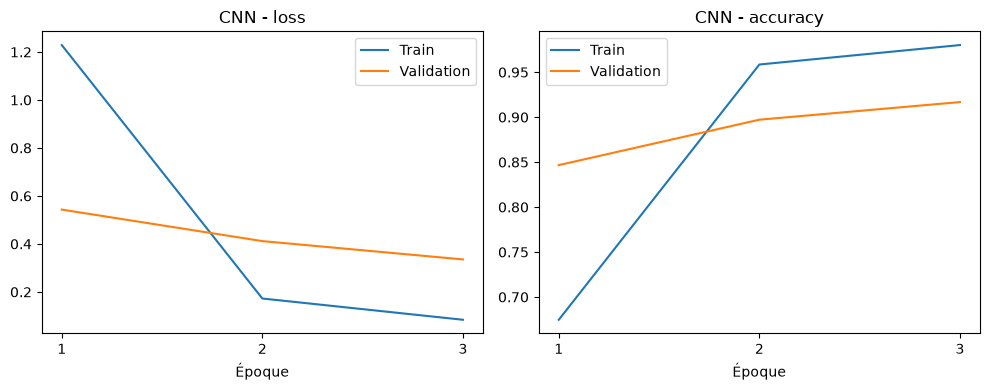

In [12]:
debut = perf_counter()
history_cnn = model_cnn.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2
)
duree_cnn = perf_counter() - debut

afficher_courbes(history_cnn, "CNN")

### Évolution de l'apprentissage du CNN
Entre la première et la deuxième époque, la loss d'entraînement chute de **1,2288 à 0,1725**, soit une baisse d'environ **86 %**. L'accuracy du train passe de **67,47 % à 95,86 %** : le modèle apprend très vite au début. La validation progresse aussi, de **84,67 % à 89,72 %**, donc cette amélioration ne concerne pas seulement les images d'entraînement.

Entre la deuxième et la troisième époque, les gains sont plus faibles. L'accuracy de validation passe de **89,72 % à 91,68 %**, soit **1,96 point** gagné contre **5,05 points** auparavant. La loss du train passe tout de même de **0,1725 à 0,0839**, et celle de validation de **0,4118 à 0,3354**. L'apprentissage ralentit, mais il reste utile : on ne peut pas encore dire que le modèle stagne.

À la fin, on a **98,02 % en train contre 91,68 % en validation**. Cet écart d'environ **6,34 points** montre que les images non utilisées pour apprendre restent plus difficiles. Il faut le surveiller, mais il ne suffit pas à conclure à du surapprentissage : la loss de validation continue de diminuer. Si elle commence à remonter alors que la loss du train baisse encore, poursuivre l'entraînement risque de surtout améliorer les résultats sur les images déjà vues.

## 5. Comparaison et premières erreurs
On compare les modèles **à la dernière époque**, avec la même séparation des données et les mêmes réglages d'entraînement. Les temps dépendent de la machine utilisée.

Il s'agit de scores de **validation**, pas de scores sur le test officiel. Trois époques ne suffisent pas pour conclure sur le meilleur modèle possible.

In [13]:
comparaison = pd.DataFrame([
    {"Essai": "Dense 128", "Paramètres": model_dense.count_params(),
     "Époques": EPOCHS, "Batch": BATCH_SIZE, "Learning rate": 0.001,
     "Accuracy train": history_dense.history["accuracy"][-1],
     "Accuracy validation": history_dense.history["val_accuracy"][-1],
     "Loss validation": history_dense.history["val_loss"][-1],
     "Durée (s)": round(duree_dense, 1)},
    {"Essai": "CNN 32-64, dense 128", "Paramètres": model_cnn.count_params(),
     "Époques": EPOCHS, "Batch": BATCH_SIZE, "Learning rate": 0.001,
     "Accuracy train": history_cnn.history["accuracy"][-1],
     "Accuracy validation": history_cnn.history["val_accuracy"][-1],
     "Loss validation": history_cnn.history["val_loss"][-1],
     "Durée (s)": round(duree_cnn, 1)}
])
display(comparaison.round(4))

,Essai,Paramètres,Époques,Batch,Learning rate,Accuracy train,Accuracy validation,Loss validation,Durée (s)
0,Dense 128,398891,3,64,0.001,0.7908,0.7313,1.0243,2.2
1,"CNN 32-64, dense 128",319979,3,64,0.001,0.9802,0.9168,0.3354,7.3


Après trois époques, le CNN atteint **91,68 %** en validation, contre **73,13 %** pour le réseau dense, soit un gain d'environ **18,55 points**. Il utilise aussi moins de paramètres : 319 979 contre 398 891.

On retient le CNN comme point de départ des prochains essais : il reconnaît davantage d'images de validation avec les mêmes données et le même nombre d'époques. Le réseau dense reste la référence de comparaison.

### Matrice de confusion du CNN sur la validation
Les lignes sont les vraies classes et les colonnes les prédictions. La diagonale contient les bonnes réponses. Les numéros correspondent au tableau des panneaux de la partie 2.

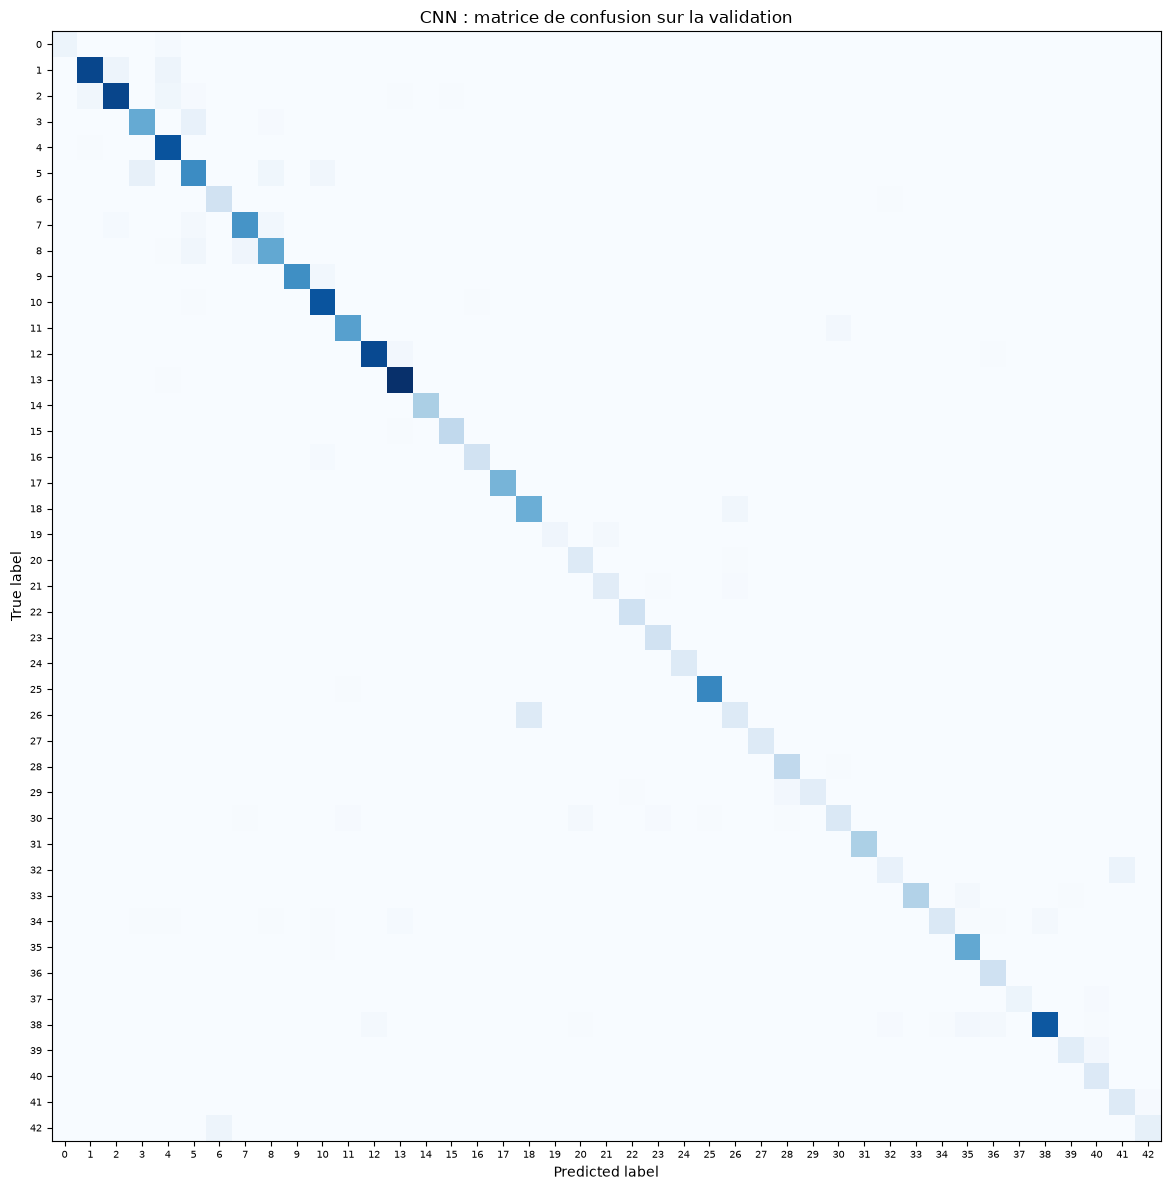

,precision,recall,f1-score,support
Limitation 20 km/h,1.000,0.800,0.889,30.000
Limitation 30 km/h,0.953,0.907,0.929,450.000
Limitation 50 km/h,0.934,0.909,0.921,450.000
Limitation 60 km/h,0.847,0.859,0.853,270.000
Limitation 70 km/h,0.883,0.990,0.933,390.000
Limitation 80 km/h,0.826,0.803,0.814,360.000
Fin de limitation 80 km/h,0.806,0.967,0.879,90.000
Limitation 100 km/h,0.929,0.910,0.919,300.000
Limitation 120 km/h,0.860,0.867,0.863,270.000
Dépassement interdit,0.993,0.943,0.968,300.000


In [14]:
predictions = model_cnn.predict(x_val, batch_size=BATCH_SIZE, verbose=0)
y_pred = np.argmax(predictions, axis=1)
cm = confusion_matrix(labels_val, y_pred, labels=range(NB_CLASSES))

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=range(NB_CLASSES)).plot(
    ax=ax, include_values=False, cmap="Blues", colorbar=False
)
ax.set_title("CNN : matrice de confusion sur la validation")
ax.tick_params(axis="both", labelsize=7)
plt.tight_layout()
plt.show()

rapport = classification_report(
    labels_val, y_pred, labels=list(range(NB_CLASSES)),
    target_names=noms_classes, output_dict=True, zero_division=0
)
display(pd.DataFrame(rapport).T.round(3))

Le rappel indique quelle proportion d'une classe est retrouvée. La précision indique quelle proportion des prédictions d'une classe est correcte. Le F1 combine les deux. La moyenne macro donne autant de poids à chaque classe, ce qui complète l'accuracy quand les classes sont déséquilibrées.

In [15]:
# On enlève la diagonale pour chercher les confusions les plus fréquentes.
confusions = cm.copy()
np.fill_diagonal(confusions, 0)
indices = np.argsort(confusions.ravel())[::-1][:5]
for indice in indices:
    vrai, predit = np.unravel_index(indice, confusions.shape)
    if confusions[vrai, predit] > 0:
        print(noms_classes[vrai], "->", noms_classes[predit], ":", confusions[vrai, predit])

print("Nombre d'erreurs :", np.sum(y_pred != labels_val), "/", len(labels_val))

Feux tricolores -> Danger : 59
Limitation 80 km/h -> Limitation 60 km/h : 36
Limitation 60 km/h -> Limitation 80 km/h : 33
Fin des interdictions -> Fin d'interdiction de dépasser : 27
Limitation 30 km/h -> Limitation 50 km/h : 21
Nombre d'erreurs : 654 / 7859


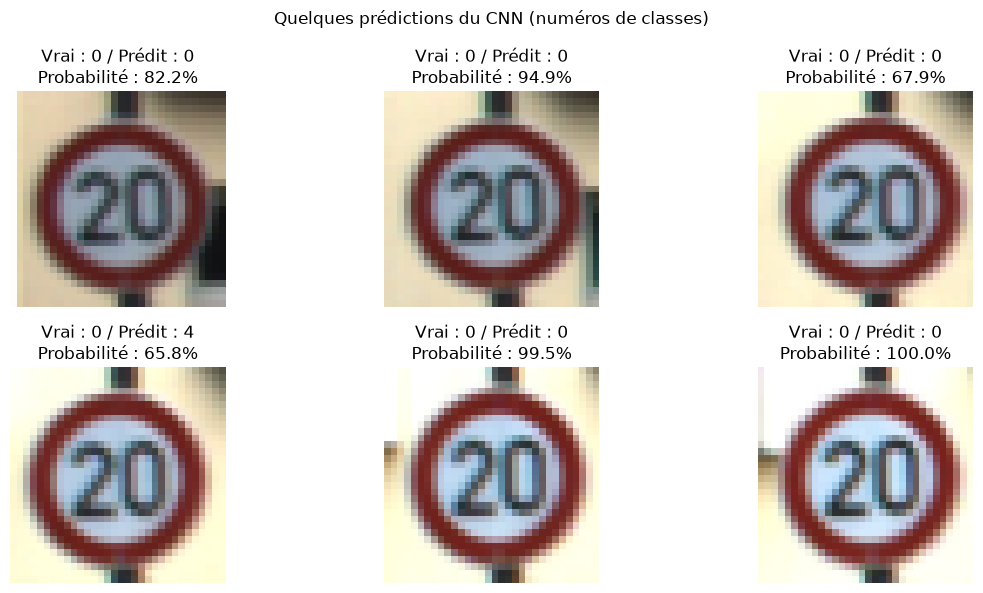

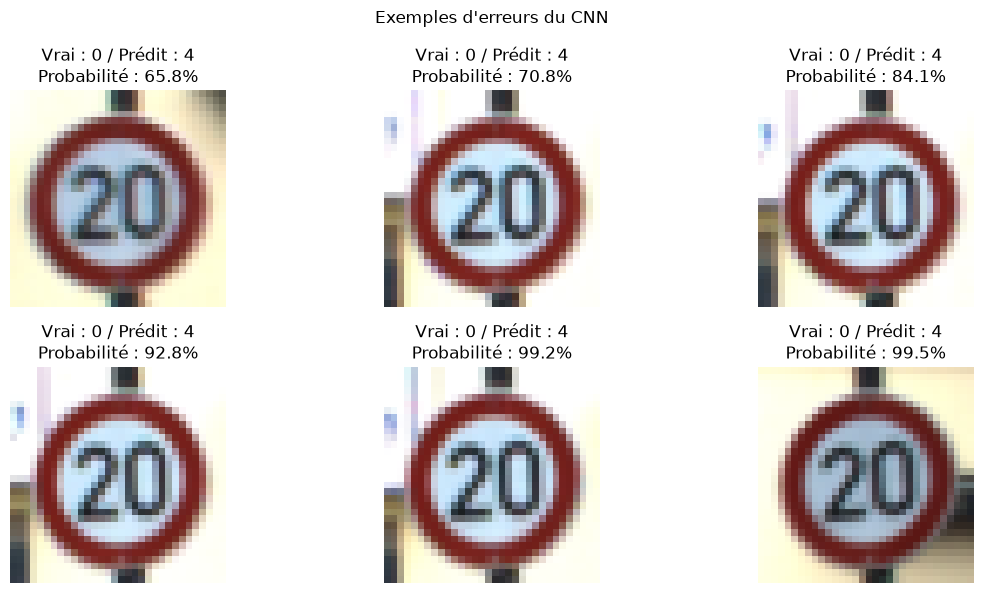

In [16]:
def afficher_predictions(indices, titre):
    plt.figure(figsize=(12, 6))
    for position, i in enumerate(indices):
        plt.subplot(2, 3, position + 1)
        plt.imshow(x_val[i])
        proba = predictions[i, y_pred[i]]
        plt.title(f"Vrai : {labels_val[i]} / Prédit : {y_pred[i]}\nProbabilité : {proba:.1%}")
        plt.axis("off")
    plt.suptitle(titre)
    plt.tight_layout()
    plt.show()

afficher_predictions(range(6), "Quelques prédictions du CNN (numéros de classes)")

erreurs = np.flatnonzero(y_pred != labels_val)
if len(erreurs) > 0:
    afficher_predictions(erreurs[:6], "Exemples d'erreurs du CNN")
else:
    print("Aucune erreur trouvée sur cette validation.")

### Choix des exemples d'erreurs
Les six premières erreurs viennent du même panneau 20 km/h, prédit 70 km/h. Cet affichage ne montre donc pas la variété des erreurs.

On affiche ensuite une image par séquence, puis six séquences tirées au hasard avec une graine fixe. Cela change seulement les exemples montrés, pas l'entraînement ni les scores.

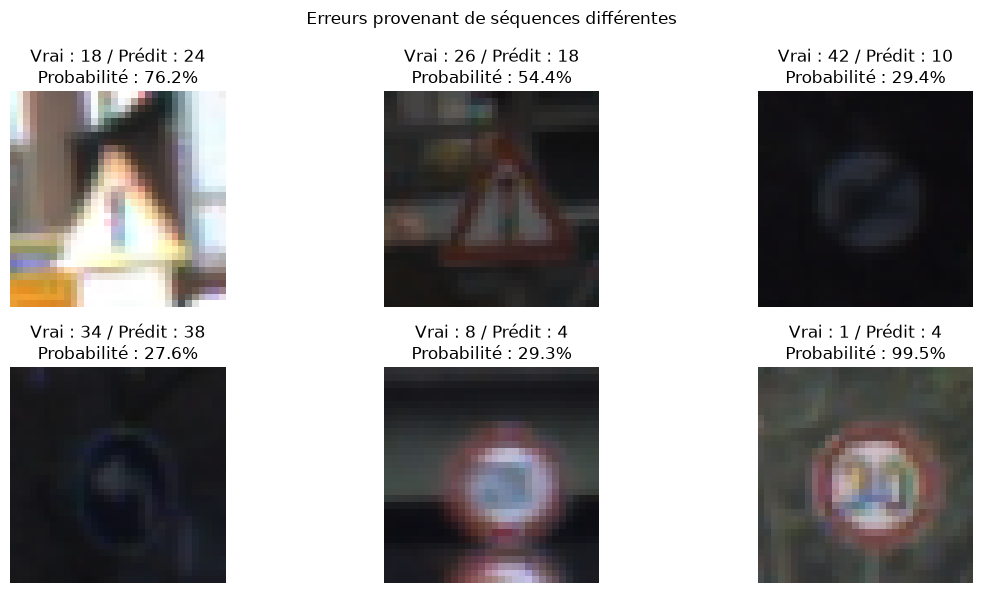

Image 5130 : Danger -> Chaussée rétrécie à droite
Image 6031 : Feux tricolores -> Danger
Image 7799 : Fin d'interdiction de dépasser pour poids lourds -> Dépassement interdit aux poids lourds
Image 6779 : Tourner à gauche -> Contournement par la droite
Image 2460 : Limitation 120 km/h -> Limitation 70 km/h
Image 331 : Limitation 30 km/h -> Limitation 70 km/h


In [17]:
# Les index correspondent toujours aux positions des images dans x_val.
erreurs_par_sequence = donnees_val.iloc[erreurs].drop_duplicates("sequence").index.to_numpy()
rng = np.random.default_rng(SEED)
exemples_erreurs = rng.choice(erreurs_par_sequence, size=min(6, len(erreurs_par_sequence)), replace=False)
if len(exemples_erreurs) > 0:
    afficher_predictions(exemples_erreurs, "Erreurs provenant de séquences différentes")
    for i in exemples_erreurs:
        print("Image", i, ":", noms_classes[labels_val[i]], "->", noms_classes[y_pred[i]])
else:
    print("Aucune erreur à afficher.")

Le CNN fait **654 erreurs sur 7 859 images** de validation. La confusion la plus fréquente est « feux tricolores » prédit « danger » : 59 images. Le rappel de la classe « feux tricolores » est de 47,5 %. À l'inverse, le rappel atteint 99,3 % pour Stop et 100 % pour Sens interdit sur cette validation.

Dans les exemples affichés, certains panneaux sont très sombres et d'autres sont flous. Les panneaux de danger partagent une forme triangulaire ; les limitations de vitesse ont un contour similaire. Ces ressemblances et le manque de détails peuvent contribuer aux erreurs, sans que ces images suffisent à prouver leur cause.

Un panneau 30 km/h est prédit 70 km/h avec une probabilité de 99,5 %. La sortie Softmax peut donc être élevée même quand la réponse est fausse.

Le F1 macro vaut environ **0,892**, contre une accuracy de **0,917**. Les scores varient selon les classes. Certaines classes de validation ne contiennent que 30 images issues d'une même séquence : leurs scores doivent être interprétés avec prudence.

## 6. Expériences suivantes
La progression du CNN ralentit, mais sa loss de validation baisse encore. On essaiera d'abord six époques pour voir si les gains continuent ou si le modèle commence à surapprendre. Une couche dense plus petite et le Dropout permettront ensuite de vérifier si on peut limiter l'écart entre train et validation.

| Essai prévu | Changement par rapport au CNN de départ | Ce qu'on veut vérifier |
|---|---|---|
| 3 | Passer de 3 à 6 époques | Le modèle a-t-il surtout besoin de plus d'entraînement ? |
| 4 | Passer de 128 à 64 neurones dans la couche dense | Peut-on réduire le modèle sans perdre trop en validation ? |
| 5 | Ajouter un Dropout de 0,3 avant la dernière couche | Cela réduit-il l'écart train / validation ? |

Ces trois essais ne sont pas encore exécutés. On gardera le même split et on repartira d'un modèle neuf pour chaque comparaison. Pour isoler l'effet des époques, l'essai 3 reprendra aussi la même graine et les mêmes réglages que l'essai 2.

Le choix final se fera sur la validation. Le modèle retenu sera ensuite évalué sur les 12 630 images du test officiel.

## 7. Détection de panneaux dans une scène
La classification actuelle suppose que le panneau est déjà extrait. Pour traiter une image de route complète, on prévoit la chaîne suivante :

Image de route → YOLO localise les panneaux → extraction des zones → le CNN reconnaît chaque panneau.

Il faudra utiliser un détecteur entraîné sur des panneaux ou l'adapter à ces données. Un modèle standard entraîné sur COCO ne couvre pas toutes les catégories recherchées.

Les zones extraites devront être converties en RGB, redimensionnées en 32 × 32 et divisées par 255. La détection n'est pas encore implémentée. La vidéo pourra être testée après la détection sur image.

## 8. Résultats et limites
Le CNN obtient de meilleurs résultats que le réseau dense dans cette comparaison : 91,68 % contre 73,13 % en validation. Les deux entraînements utilisent 31 350 images, puis sont évalués sur 7 859 images provenant de séquences distinctes.

| Essai réalisé le 15 octobre 2026 | Résultat en validation | Décision |
|---|---|---|
| Dense 128, 3 époques | Accuracy 73,13 %, loss 1,0243 | Référence de comparaison |
| CNN 32-64, dense 128, 3 époques | Accuracy 91,68 %, loss 0,3354 | Base pour les expériences suivantes |
| Affichage des six premières erreurs | Six images du même panneau | Ajouter un échantillon de séquences différentes |

Ces résultats concernent une seule séparation train / validation et trois époques. Les expériences supplémentaires, l'évaluation sur le test officiel et la détection restent à réaliser.

Références : [GTSRB](https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/published-archive.html), [documentation Keras](https://keras.io/api/utils/python_utils/).